In [3]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras import layers
import warnings; warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("Churn_Modelling.csv")
def describe(df):
    print("Shape: ", df.shape)
    print("\nFirst 5 rows:");  print(df.head())
    print("\nLast 5 rows:");   print(df.tail())
    print("\nInfo:");          df.info()
    print("\nStatistics:");    print(df.describe())
    print("\nMissing values:"); print(df.isnull().sum())
describe(df)
df = df.drop(columns=["RowNumber","CustomerId","Surname"])                # useless ID columns
df["Gender"] = LabelEncoder().fit_transform(df["Gender"])
df = pd.get_dummies(df, columns=["Geography"], drop_first=True, dtype=int)
X, y = df.drop(columns=["Exited"]), df["Exited"]
print(y.value_counts())

Shape:  (10000, 14)

First 5 rows:
   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3      

In [4]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
sc = StandardScaler(); X_train = sc.fit_transform(X_train); X_test = sc.transform(X_test)

model = tf.keras.Sequential([tf.keras.Input(shape=(X_train.shape[1],)),
                             layers.Dense(16,activation="relu"),
                             layers.Dense(8,activation="relu"),
                             layers.Dense(1,activation="sigmoid")])
model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])
h = model.fit(X_train,y_train,validation_split=0.2,epochs=30,batch_size=32,verbose=0)

E0000 00:00:1793714031.870899    6483 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Accuracy: 0.8625
[[1545   48]
 [ 227  180]]
              precision    recall  f1-score   support

           0       0.87      0.97      0.92      1593
           1       0.79      0.44      0.57       407

    accuracy                           0.86      2000
   macro avg       0.83      0.71      0.74      2000
weighted avg       0.86      0.86      0.85      2000

First test customer -> Will STAY


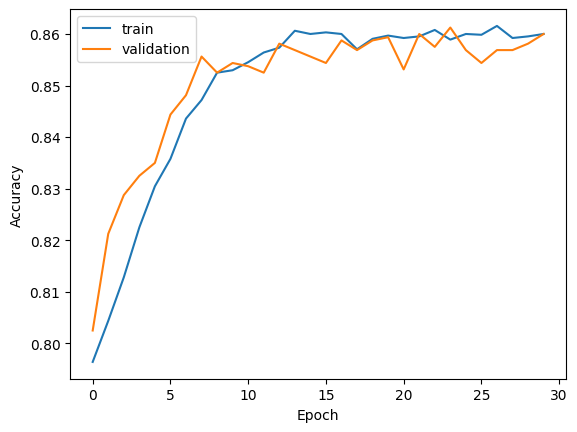

In [5]:
pred = (model.predict(X_test)>0.5).astype(int)
print("Accuracy:",accuracy_score(y_test,pred))
print(confusion_matrix(y_test,pred)); print(classification_report(y_test,pred))
print("First test customer ->", "Will LEAVE" if pred[0][0]==1 else "Will STAY")

plt.plot(h.history["accuracy"],label="train"); plt.plot(h.history["val_accuracy"],label="validation")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.show()